<a href="https://colab.research.google.com/github/adornkjoshy30-pixel/Healthcare-Workflow-Intelligence/blob/main/KMeans_Cluster_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip -q install plotly

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

from google.colab import files

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries Loaded ")

Libraries Loaded 


In [9]:
uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)
#

print("Data Set Loaded")
print("Rows and Columns:", df.shape)
df.head()

Saving Mall_Customers.csv to Mall_Customers (2).csv
Data Set Loaded
Rows and Columns: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [10]:
print("\nSummary statistics:")
display(df.describe)


Summary statistics:


<bound method NDFrame.describe of      CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]>

In [11]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [12]:
print("\nDuplicate rows:", df.duplicated().sum)


Duplicate rows: <bound method Series.sum of 0      False
1      False
2      False
3      False
4      False
       ...  
195    False
196    False
197    False
198    False
199    False
Length: 200, dtype: bool>


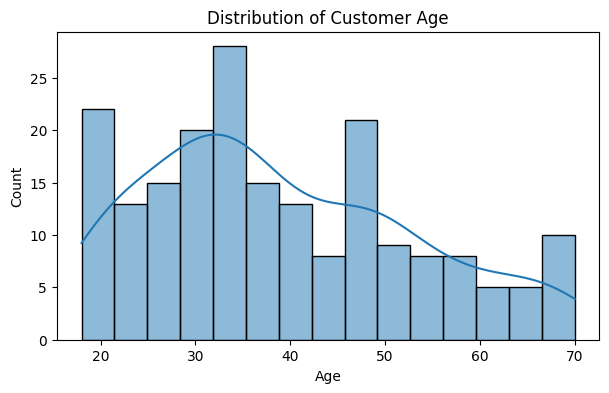

In [14]:
# Explore Customer Data
plt.figure(figsize=(7, 4))
sns.histplot(df["Age"], bins=15, kde=True)
plt.title('Distribution of Customer Age')
plt.show()

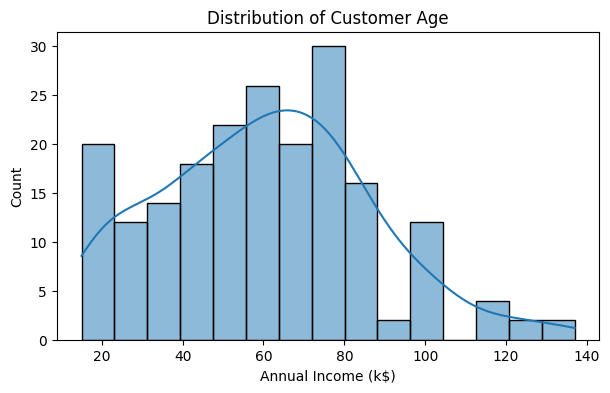

In [15]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Annual Income (k$)"], bins=15, kde=True)
plt.title('Distribution of Customer Age')
plt.show()

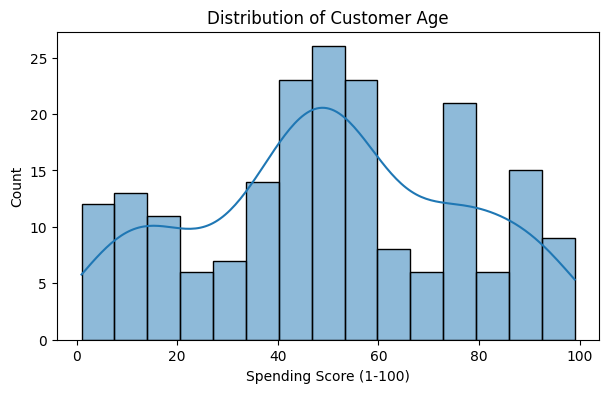

In [16]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Spending Score (1-100)"], bins=15, kde=True)
plt.title('Distribution of Customer Age')
plt.show()

In [17]:
# SELECT FEATURES FOR CLUSTERING

# We will cluster customers using two features:
# Annual Income and Spending Score
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
print("Features selected:")
display(X.head())

Features selected:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [18]:
#scaling

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("features scaled")
display(X.head())


features scaled


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


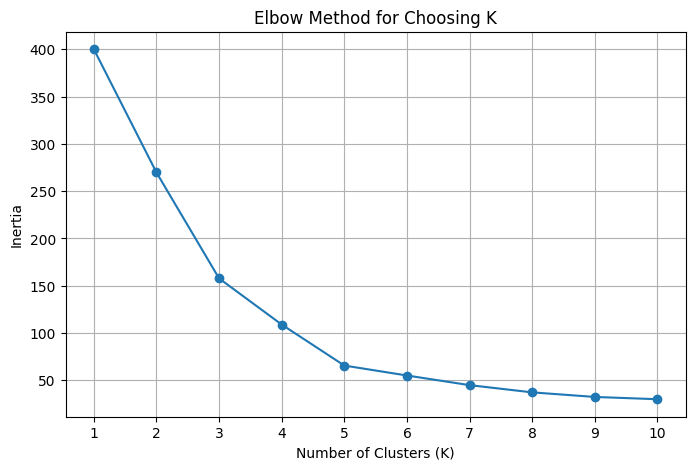

In [19]:
# FIND THE OPTIMAL K USING THE ELBOW METHOD
# Test K-Means with different numbers of cluster
inertia_values = []
for k in range(1, 11):
  model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
  model.fit(X_scaled)
  inertia_values.append(model.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, 11),
    inertia_values,
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing K")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


In [20]:
# EVALUATE CLUSTER COUNTS USING SILHOUETTE SCORE
# Silhouette scores range from -1 to 1.
# Higher scores generally indicate better-separated clusters.
for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
labels = model.fit_predict(X_scaled)
score = silhouette_score(X_scaled, labels)
print("K =", k, "| Silhouette Score =", round(score, 3))

K = 8 | Silhouette Score = 0.455


In [21]:
# BUILD THE K-MEANS MODEL
# Five clusters are a common optimal cluster for this dataset.
# Students should compare this choice with the elbow and scores.
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)
print("K-Means model completed!")
display(
    df[[
        "CustomerID",
        "Annual Income (k$)",
        "Spending Score (1-100)",
        "KMeans_Cluster"
    ]].head(10)
)

K-Means model completed!


,CustomerID,Annual Income (k$),Spending Score (1-100),KMeans_Cluster
0,1,15,39,4
1,2,15,81,2
2,3,16,6,4
3,4,16,77,2
4,5,17,40,4
5,6,17,76,2
6,7,18,6,4
7,8,18,94,2
8,9,19,3,4
9,10,19,72,2


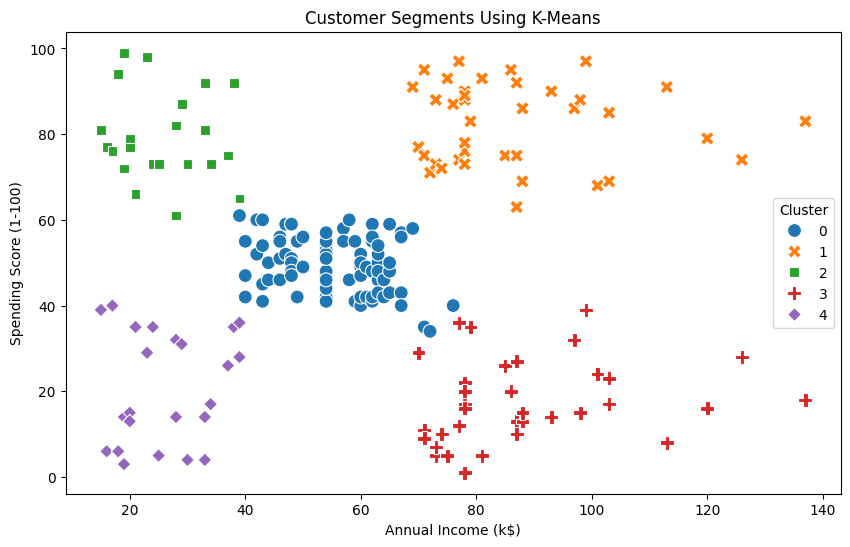

In [22]:
# VISUALIZE K-MEANS CLUSTERS

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Cluster",
    palette="tab10",
    s=100,
    style="KMeans_Cluster"
)

plt.title("Customer Segments Using K-Means")
plt.legend(title="Cluster")
plt.show()

In [23]:
# INTERPRET THE CUSTOMER SEGMENTS

# Calculate the average income and spending score
# for each cluster.

cluster_summary = df.groupby("KMeans_Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)

print("Customer Segment Summary:")
display(cluster_summary)

Customer Segment Summary:


,Customer_Count,Average_Age,Average_Income,Average_Spending
KMeans_Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [24]:
# INTERACTIVE K-MEANS VISUALIZATION
fig = px.scatter(
    df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    color="KMeans_Cluster",
    hover_data=["CustomerID", "Age", "Gender"],
    title="Interactive Mall Customer Segmentation",
    labels={
        "Annual Income (k$)": "Annual Income (thousands of dollars)",
        "Spending Score (1-100)": "Spending Score",
        "KMeans_Cluster": "Cluster"
    }
)
fig.update_traces(marker=dict(size=12))
fig.show(render="browser")